# Proyecto final: Análisis y pronóstico de series de tiempo
## Precio de apertura del S&P 500 (2015-2020)

**Integrantes:**  Jose Arenas, Mauricio Blanco, Jhonier Correa  
**Curso:** Series de tiempo / Forecasting
**Base de datos:** [Time Series Forecasting with Yahoo Stock Price](https://www.kaggle.com/datasets/arashnic/time-series-forecasting-with-yahoo-stock-price) (Kaggle, archivo `yahoo_stock.csv`)



## 1. Introducción al análisis de series de tiempo

**El fenómeno.** El S&P 500 reúne a las ~500 mayores empresas cotizadas de Estados Unidos y es el termómetro más usado de la economía de ese país y, en buena parte, de la mundial. Su precio determina el valor de fondos de pensiones, ETF y portafolios de ahorro, y es insumo de decisiones de inversión, gestión de riesgo y política económica.

**La base de datos.** `yahoo_stock.csv` contiene 1 825 registros diarios entre el 2015-11-23 y el 2020-11-20 con precios de apertura, máximo, mínimo, cierre, cierre ajustado y volumen. El periodo es especialmente interesante porque incluye una fase de crecimiento sostenido, la corrección de febrero de 2018, la caída de diciembre de 2018 y el desplome y rebote de la pandemia de COVID-19 (feb-abr 2020).

**Motivación.** Se trata de una serie con *tendencia fuerte*, *volatilidad cambiante* y *eventos extremos*, es decir, justo las características que ponen a prueba las herramientas del curso (estacionariedad, diferenciación, ARIMA, validación de pronósticos). Además, permite hacer una pregunta con valor práctico: **¿se puede pronosticar el precio de apertura del índice a un mes vista mejor que con la regla más simple de "mañana será igual que hoy"?** Responderla con honestidad (incluso si la respuesta es "apenas") es parte del objetivo del trabajo.

**Objetivos específicos**
1. Explorar y describir la serie (tendencia, estacionalidad, volatilidad, distribución).
2. Depurarla y transformarla para que cumpla los supuestos de los modelos.
3. Ajustar un modelo ARIMA (`statsmodels`) y un modelo de aprendizaje automático (SVR, `scikit-learn`) para pronosticar.
4. Evaluar ambos con métricas y validación temporal, contra un modelo de referencia, e interpretar limitaciones y mejoras.


### Ruta de trabajo

| Etapa | Qué se hace | Por qué |
|---|---|---|
| 2. Exploración | Calidad de datos, gráficos, descomposición, ACF/PACF, estadísticos | Conocer la serie *antes* de modelarla y detectar problemas en los datos |
| 3. Preparación | Serie de días hábiles, retornos logarítmicos, pruebas ADF/KPSS, partición temporal | Que la serie cumpla los supuestos y que la evaluación no use información del futuro |
| 4. Modelado | ARIMA elegido por criterios de información, SVR con *lags*, referencia ingenua | Comparar un modelo estadístico, uno de ML y un modelo de referencia |
| 5. Evaluación | MAE, RMSE, MAPE, MASE, cobertura de intervalos, diagnóstico de residuos | Juzgar si el modelo realmente aporta y dónde falla |


## Dependencias

In [ ]:
import os
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
SEED = 42
np.random.seed(SEED)

## Carga de datos

In [ ]:
# Si ya tiene yahoo_stock.csv en la carpeta del notebook, se usa directamente;
# de lo contrario se descarga desde Kaggle con kagglehub (pip install kagglehub).
if os.path.exists("yahoo_stock.csv"):
    ruta = "yahoo_stock.csv"
else:
    import kagglehub
    path = kagglehub.dataset_download("arashnic/time-series-forecasting-with-yahoo-stock-price")
    ruta = os.path.join(path, "yahoo_stock.csv")

df_raw = pd.read_csv(ruta, parse_dates=["Date"])
print("Dimensiones:", df_raw.shape)
df_raw.head()

Dimensiones: (1825, 7)


,Date,High,Low,Open,Close,Volume,Adj Close
0,2015-11-23,2095.610107,2081.389893,2089.409912,2086.590088,3.587980e+09,2086.590088
1,2015-11-24,2094.120117,2070.290039,2084.419922,2089.139893,3.884930e+09,2089.139893
2,2015-11-25,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
3,2015-11-26,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
4,2015-11-27,2093.290039,2084.129883,2088.820068,2090.110107,1.466840e+09,2090.110107


## 2. Exploración de la base de datos

### 2.1 ¿Qué información se obtiene al visualizar una serie de tiempo?

Graficar la serie contra el tiempo es el primer paso de cualquier análisis porque deja ver, antes de calcular nada, la estructura que el modelo deberá capturar:

| Aspecto | Qué revela | Por qué importa para el modelado | Qué esperamos en esta serie |
|---|---|---|---|
| **Tendencia** | Dirección de largo plazo (crece, decrece, estable) | Una tendencia indica que la media no es constante, así que la serie no es estacionaria y hay que diferenciar | Alcista en 2016-2019 |
| **Estacionalidad** | Patrones que se repiten con periodo fijo (semana, mes, año) | Si existe, se modela con componentes estacionales (SARIMA) o variables de calendario | A comprobar: no es evidente a simple vista |
| **Volatilidad y valores atípicos** | Variabilidad de corto plazo, saltos y datos extremos | La varianza no constante afecta los intervalos de confianza; los atípicos pueden distorsionar el ajuste | *Clusters* de volatilidad, sobre todo en 2018 y 2020 |
| **Rupturas estructurales / ciclos** | Cambios bruscos de nivel o de comportamiento por eventos externos | El modelo asume un proceso estable, y una ruptura lo invalida localmente | Caída por COVID-19 en febrero-marzo de 2020 |
| **Dependencia temporal** | Si los valores cercanos se parecen (visible en ACF/PACF) | Es la materia prima de los modelos AR/MA | Se cuantifica en 2.3 |


### 2.2 Variables disponibles y naturaleza de los datos

| Variable | Descripción | Naturaleza | ¿Se usa? |
|---|---|---|---|
| `Date` | Fecha del registro | Temporal (diaria) | Sí, como **índice** de la serie |
| `Open` | Precio de apertura del índice | Cuantitativa continua | Sí, es la **variable objetivo** |
| `High` / `Low` | Máximo y mínimo del día | Cuantitativa continua | No (están casi perfectamente correlacionadas con `Open`) |
| `Close` / `Adj Close` | Cierre y cierre ajustado | Cuantitativa continua | No (idénticos entre sí en un índice) |
| `Volume` | Volumen transado | Cuantitativa discreta (en la práctica, continua) | No |

**Naturaleza de la serie:** es una serie **univariada** (una sola variable observada en el tiempo), de frecuencia **diaria**, con observaciones **equiespaciadas** en el calendario.

**¿Por qué `Open`?** Se mantiene la variable que ya se había elegido en el trabajo. El precio de apertura es el primer precio negociado del día, por lo que es un objetivo de pronóstico razonable (es el precio al que un inversionista ejecutaría una orden a la apertura). Las demás variables son derivadas del mismo precio, así que incluirlas no aporta información nueva a un modelo univariado y sí riesgo de *fuga de información* (por ejemplo, `Close` del mismo día no se conoce a la apertura).

A continuación se revisa la calidad de los datos crudos.


In [ ]:
df_raw.info()
print()
print("Valores nulos por columna:\n", df_raw.isna().sum(), sep="")
print("\nFechas duplicadas:", df_raw["Date"].duplicated().sum())
print(f"Rango de fechas: {df_raw['Date'].min().date()} -> {df_raw['Date'].max().date()}")
print("Diferencia entre fechas consecutivas:\n", df_raw["Date"].diff().value_counts(), sep="")

<class 'pandas.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1825 non-null   datetime64[us]
 1   High       1825 non-null   float64       
 2   Low        1825 non-null   float64       
 3   Open       1825 non-null   float64       
 4   Close      1825 non-null   float64       
 5   Volume     1825 non-null   float64       
 6   Adj Close  1825 non-null   float64       
dtypes: datetime64[us](1), float64(6)
memory usage: 99.9 KB

Valores nulos por columna:
Date         0
High         0
Low          0
Open         0
Close        0
Volume       0
Adj Close    0
dtype: int64

Fechas duplicadas: 0
Rango de fechas: 2015-11-23 -> 2020-11-20
Diferencia entre fechas consecutivas:
Date
1 days    1824
Name: count, dtype: int64


**Hallazgo importante de calidad de datos.** El archivo trae 1 825 filas con fechas consecutivas, **incluyendo sábados y domingos**, y la bolsa no opera esos días. La revisión muestra que el 100 % de los registros de fin de semana repite exactamente el valor del viernes anterior (es decir, fueron rellenados con el último dato conocido).

Esto no es un detalle menor porque:
- **Introduce ceros artificiales** en las diferencias (casi 3 de cada 10 "días" no tienen variación real).
- **Crea una falsa estacionalidad semanal** (patrón de 7 días en el que dos de cada siete valores son copias).
- **Subestima la volatilidad diaria** y distorsiona ACF/PACF y la estimación de cualquier ARIMA.
- Hace que "predecir 24 días" en el trabajo anterior equivaliera a solo ~17 días de mercado.


In [ ]:
# ¿Qué valor tiene 'Open' en sábados/domingos comparado con el viernes anterior?
d = df_raw.set_index("Date")["Open"]
fin_semana = d[d.index.dayofweek >= 5]
viernes_previo = pd.Series([d[:f][d[:f].index.dayofweek == 4].iloc[-1] for f in fin_semana.index], index=fin_semana.index)
print("Registros de fin de semana:", len(fin_semana))
print("Porcentaje que repite exactamente el valor del viernes:", f"{(fin_semana.values == viernes_previo.values).mean():.0%}")

print("\nRegistros por día de la semana (0=lunes ... 6=domingo):")
print(df_raw["Date"].dt.dayofweek.value_counts().sort_index().to_string())

Registros de fin de semana: 520
Porcentaje que repite exactamente el valor del viernes: 100%

Registros por día de la semana (0=lunes ... 6=domingo):
Date
0    261
1    261
2    261
3    261
4    261
5    260
6    260


**Decisión:** se eliminan los fines de semana y se trabaja con la serie de **días hábiles (frecuencia `B`)**. Quedan 1 305 observaciones reales sin huecos. Los festivos entre semana (47 casos en que el valor es idéntico al del día previo) se dejan como están, ya que son pocos (3,6 %) y eliminarlos dejaría una frecuencia irregular que `statsmodels` no puede manejar sin advertencias; se documenta como limitación.


In [ ]:
# Serie de trabajo: solo días hábiles (lunes-viernes), frecuencia 'B'
serie = (
    df_raw.loc[df_raw["Date"].dt.dayofweek < 5, ["Date", "Open"]]
    .set_index("Date")["Open"]
    .round(2)
    .asfreq("B")
)
serie.name = "Open"

print("Observaciones (días hábiles):", len(serie))
print("Nulos tras asfreq('B'):", serie.isna().sum())
print("Días hábiles con valor idéntico al anterior (festivos con relleno):", int((serie.diff() == 0).sum()))
serie.head()

Observaciones (días hábiles): 1305
Nulos tras asfreq('B'): 0
Días hábiles con valor idéntico al anterior (festivos con relleno): 47


Date
2015-11-23    2089.41
2015-11-24    2084.42
2015-11-25    2089.30
2015-11-26    2089.30
2015-11-27    2088.82
Freq: B, Name: Open, dtype: float64

### 2.3 Análisis exploratorio

**¿Qué análisis estadísticos sirven para comprender una serie de tiempo?**

1. **Gráfico de la serie y medias/desviaciones móviles:** tendencia y volatilidad.
2. **Descomposición** (tendencia + estacionalidad + residuo): separa los componentes.
3. **Contrastes de estacionalidad** sobre los retornos (boxplots por mes/día y prueba de Kruskal-Wallis).
4. **Funciones de autocorrelación (ACF) y autocorrelación parcial (PACF):** estructura de dependencia y orden candidato de un ARIMA.
5. **Pruebas de estacionariedad (ADF y KPSS)**, en la sección 3.
6. **Estadística descriptiva y pruebas de normalidad**, en 2.4.

Se grafica primero la serie con medias móviles de 21 días (~1 mes bursátil) y 252 días (~1 año bursátil), ventanas elegidas por el calendario bursátil, y la desviación estándar móvil como medida de volatilidad.


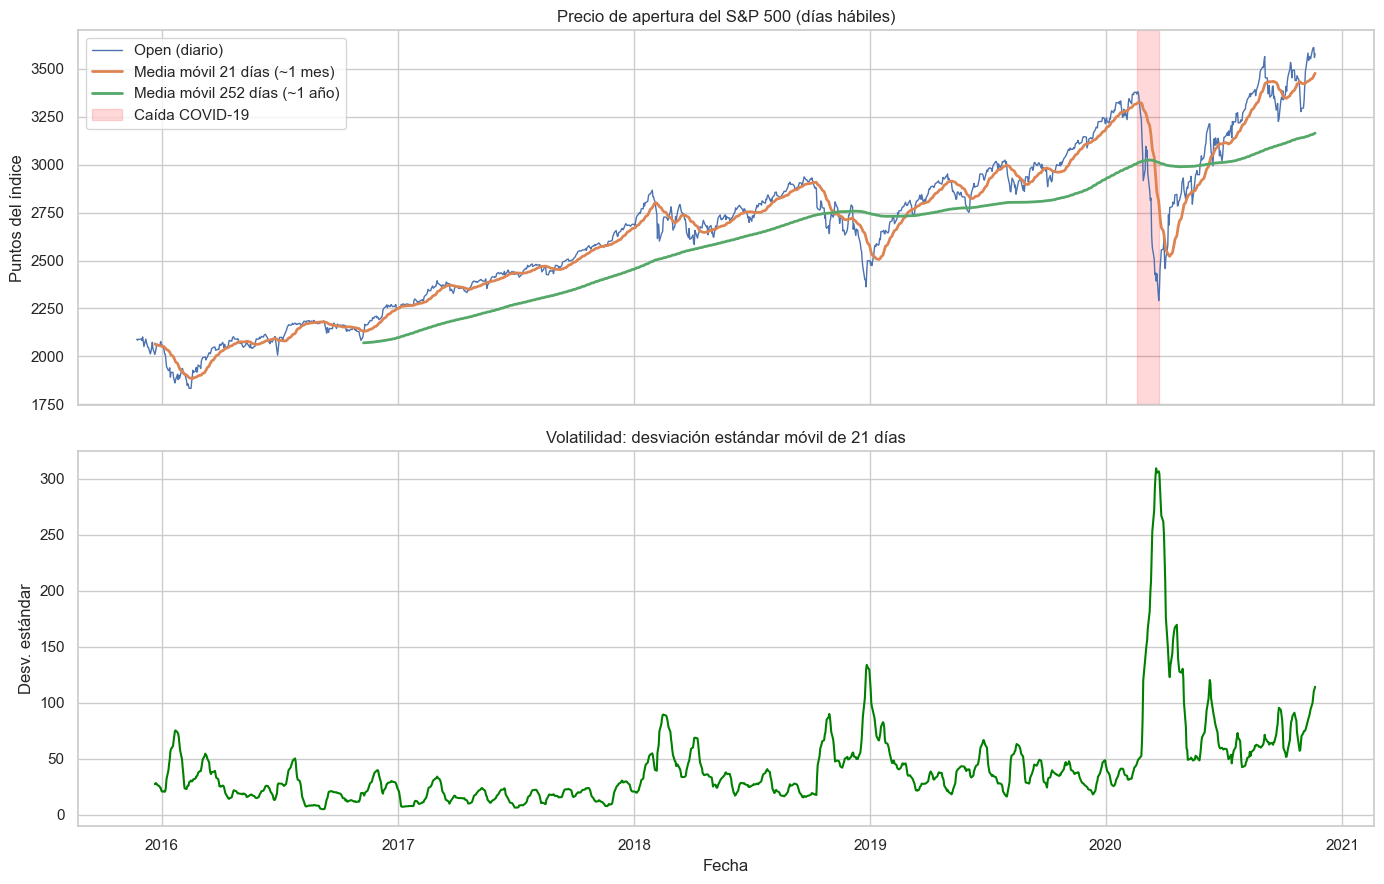

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(serie, lw=1, label="Open (diario)")
axes[0].plot(serie.rolling(21).mean(), lw=2, label="Media móvil 21 días (~1 mes)")
axes[0].plot(serie.rolling(252).mean(), lw=2, label="Media móvil 252 días (~1 año)")
axes[0].axvspan(pd.Timestamp("2020-02-19"), pd.Timestamp("2020-03-23"), color="red", alpha=0.15, label="Caída COVID-19")
axes[0].set_title("Precio de apertura del S&P 500 (días hábiles)")
axes[0].set_ylabel("Puntos del índice")
axes[0].legend(loc="upper left")

axes[1].plot(serie.rolling(21).std(), color="green", lw=1.5)
axes[1].set_title("Volatilidad: desviación estándar móvil de 21 días")
axes[1].set_ylabel("Desv. estándar")
axes[1].set_xlabel("Fecha")
plt.tight_layout()
plt.show()

**Cómo leer los gráficos siguientes.**
- *Descomposición:* se usa el modelo **multiplicativo** porque la amplitud de las oscilaciones crece con el nivel del índice (variaciones proporcionales). Se prueban tres periodos (anual 252, mensual 21, semanal 5) para ver si alguno muestra un efecto estacional relevante; el "factor estacional" vale 1 cuando no hay efecto.
- *Boxplots de retornos:* se grafican **retornos y no niveles**. El boxplot del nivel por mes (como en la versión anterior) mezcla la tendencia con la estacionalidad, y como la serie sube con los años, los meses "tardíos" siempre se ven más altos. Con retornos se aísla el efecto calendario.
- *Kruskal-Wallis:* contraste no paramétrico de que el retorno tiene la misma distribución en todos los meses (o días); se usa porque los retornos no son normales (ver 2.4).
- *ACF/PACF:* se muestran del nivel y de la serie diferenciada.


Periodo anual (252 días hábiles)     -> amplitud del factor estacional: 0.0972 (1.0000 = sin efecto)
Periodo mensual (21 días hábiles)    -> amplitud del factor estacional: 0.0036 (1.0000 = sin efecto)
Periodo semanal (5 días hábiles)     -> amplitud del factor estacional: 0.0009 (1.0000 = sin efecto)


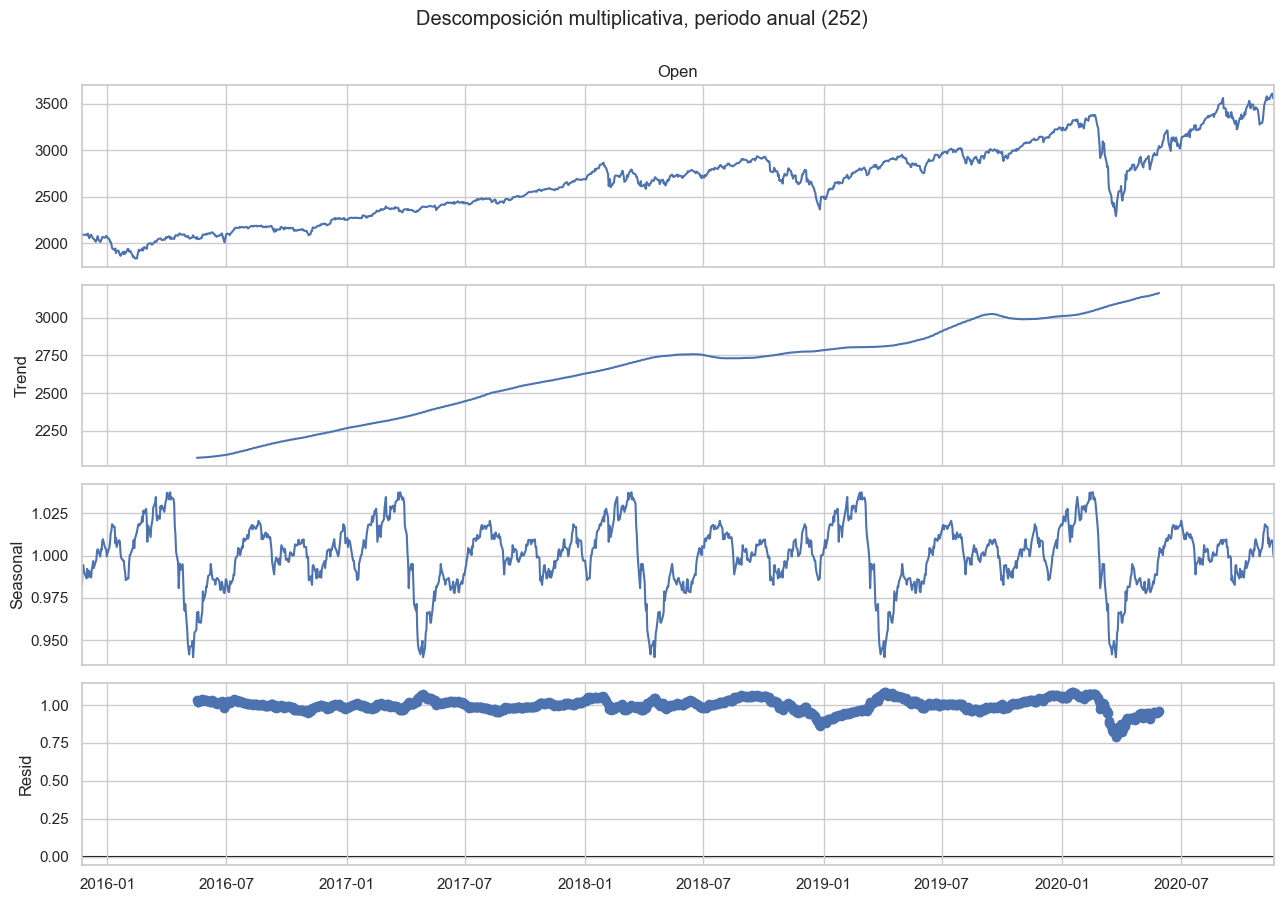

In [ ]:
# Descomposición multiplicativa (la amplitud de las oscilaciones crece con el nivel)
fig_dec = {}
for periodo, nombre in [(252, "anual (252 días hábiles)"), (21, "mensual (21 días hábiles)"), (5, "semanal (5 días hábiles)")]:
    dec = seasonal_decompose(serie, model="multiplicative", period=periodo)
    fig_dec[periodo] = dec
    amp = dec.seasonal.max() - dec.seasonal.min()
    print(f"Periodo {nombre:28s} -> amplitud del factor estacional: {amp:.4f} (1.0000 = sin efecto)")

fig = fig_dec[252].plot()
fig.set_size_inches(13, 9)
plt.suptitle("Descomposición multiplicativa, periodo anual (252)", y=1.0)
plt.tight_layout()
plt.show()

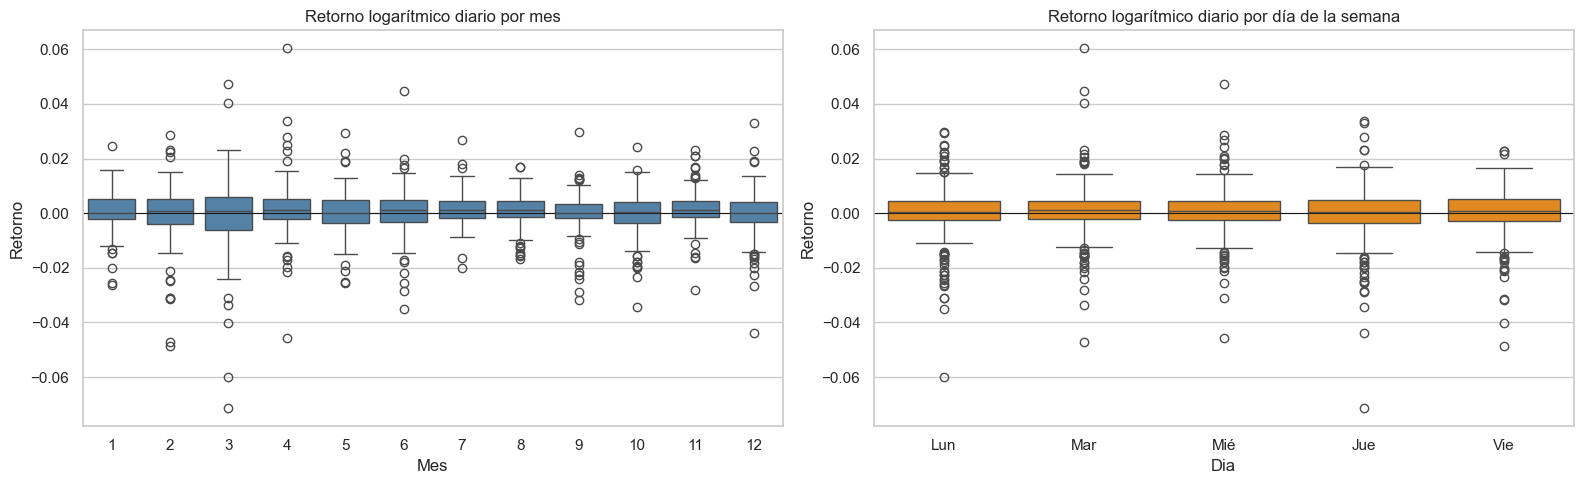

Kruskal-Wallis por mes:           H=7.07  p-valor=0.7933
Kruskal-Wallis por día de semana: H=1.46  p-valor=0.8336


In [ ]:
# Estacionalidad sobre retornos (no sobre niveles, para que la tendencia no la contamine)
ret = np.log(serie).diff().dropna()
tmp = ret.to_frame("ret")
tmp["Mes"] = tmp.index.month
tmp["Dia"] = tmp.index.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(x="Mes", y="ret", data=tmp, ax=axes[0], color="steelblue")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title("Retorno logarítmico diario por mes")
axes[0].set_ylabel("Retorno")
sns.boxplot(x="Dia", y="ret", data=tmp, ax=axes[1], color="darkorange")
axes[1].set_xticklabels(["Lun", "Mar", "Mié", "Jue", "Vie"])
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Retorno logarítmico diario por día de la semana")
axes[1].set_ylabel("Retorno")
plt.tight_layout()
plt.show()

# Pruebas formales: ¿difiere el retorno medio entre meses / días? (Kruskal-Wallis, no paramétrica)
h_mes, p_mes = stats.kruskal(*[g["ret"].values for _, g in tmp.groupby("Mes")])
h_dia, p_dia = stats.kruskal(*[g["ret"].values for _, g in tmp.groupby("Dia")])
print(f"Kruskal-Wallis por mes:           H={h_mes:.2f}  p-valor={p_mes:.4f}")
print(f"Kruskal-Wallis por día de semana: H={h_dia:.2f}  p-valor={p_dia:.4f}")

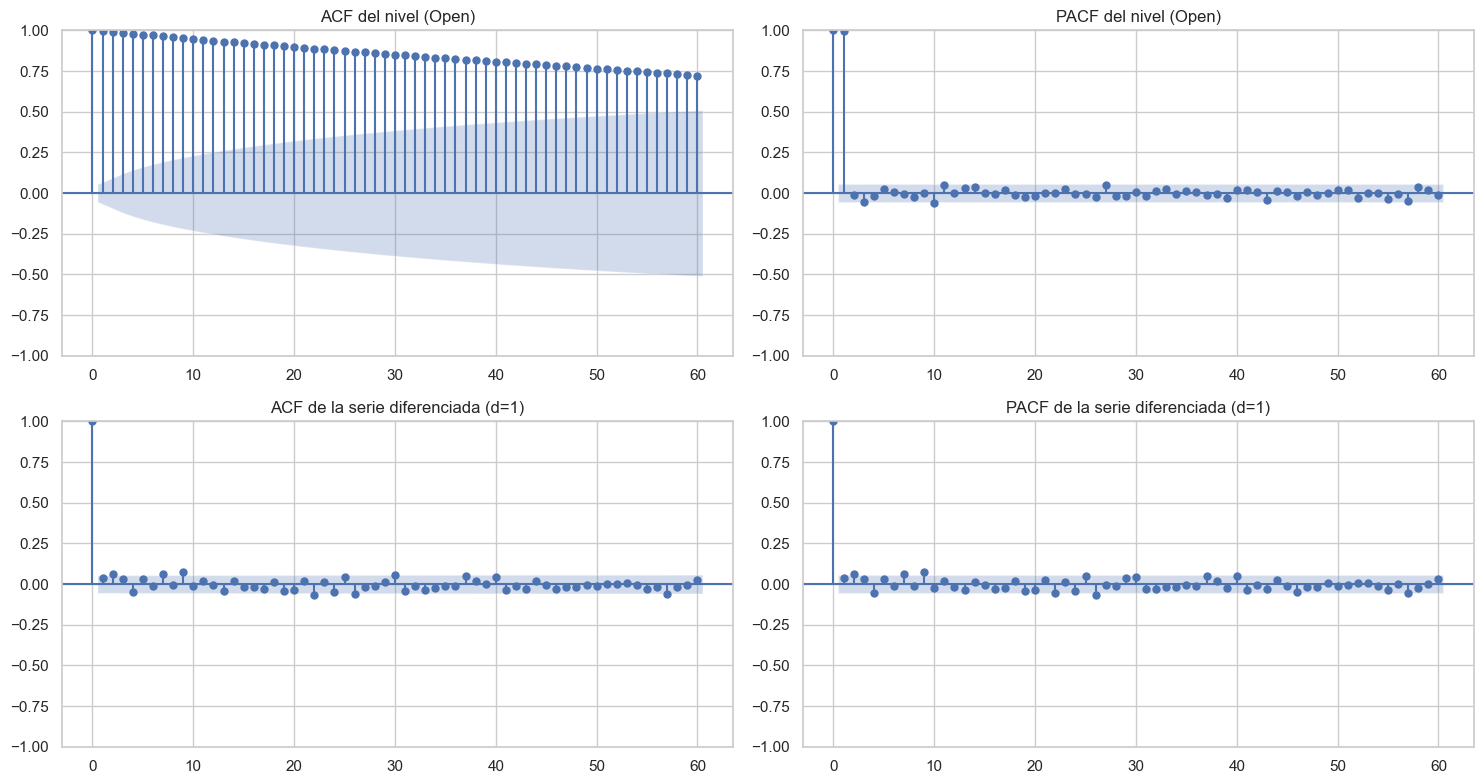

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
plot_acf(serie, lags=60, ax=axes[0, 0], title="ACF del nivel (Open)")
plot_pacf(serie, lags=60, ax=axes[0, 1], title="PACF del nivel (Open)", method="ywm")
plot_acf(serie.diff().dropna(), lags=60, ax=axes[1, 0], title="ACF de la serie diferenciada (d=1)")
plot_pacf(serie.diff().dropna(), lags=60, ax=axes[1, 1], title="PACF de la serie diferenciada (d=1)", method="ywm")
plt.tight_layout()
plt.show()

**Conclusiones del análisis exploratorio**

- **Tendencia:** clara y alcista. La media móvil anual sube de ~2 070 (nov-2016) a ~3 165 puntos (nov-2020). Se interrumpe con la caída por COVID-19 (el índice pasó de ~3 380 el 19-feb-2020 a ~2 290 en marzo) y se recupera en pocos meses. Esa recuperación en "V" es una **ruptura estructural** que ningún modelo lineal de la serie en sí anticipa.
- **Estacionalidad: no hay evidencia sólida.** Contrario a lo que se había afirmado como "aparente estacionalidad", los factores estacionales son prácticamente nulos para los periodos mensual (amplitud 0,0036) y semanal (0,0009). El anual (0,097) es engañoso: con solo ~5 años de datos hay apenas 5 ciclos y el componente "estacional" absorbe la caída de 2020. Las pruebas de Kruskal-Wallis lo confirman: no se rechaza que el retorno sea igual en todos los meses (p = 0,79) ni en todos los días de la semana (p = 0,83). Por tanto **no se justifica un modelo SARIMA**.
- **Volatilidad:** cambia en el tiempo (desv. estándar móvil entre ~5 y ~309 puntos) y se agrupa en episodios (2018, 2020). Esto se llama *heterocedasticidad condicional* y es una limitación que se retoma en la evaluación.
- **Dependencia:** el ACF del nivel decae muy lento (0,995 en el rezago 1; 0,72 en el rezago 60), típico de una serie con raíz unitaria. Tras diferenciar, las autocorrelaciones son pequeñas (|ρ| ≤ 0,073) y los pocos rezagos que cruzan las bandas (7 de 60, cuando por azar se esperan ~3) están dispersos, sin patrón. Es decir, **la serie diferenciada se parece a ruido blanco** y hay poca estructura lineal que un ARIMA pueda explotar.


### 2.4 Estadísticas descriptivas

Se calculan sobre el **nivel** del precio (lo que pide el enunciado) y sobre los **retornos logarítmicos diarios**, $r_t = \ln(P_t / P_{t-1})$. Estos últimos son la medida natural en finanzas porque son comparables entre niveles de precio, aproximadamente simétricos y, como se verá en la sección 3, estacionarios.


In [ ]:
desc = serie.describe().to_frame("Open").T
desc["mediana"] = serie.median()
desc["rango"] = serie.max() - serie.min()
desc["coef_variacion_%"] = serie.std() / serie.mean() * 100
desc["asimetria"] = stats.skew(serie)
desc["curtosis_exceso"] = stats.kurtosis(serie)
desc.round(2).T

,Open
count,1305.00
mean,2648.25
std,408.19
min,1833.40
25%,2339.79
50%,2685.49
75%,2913.86
max,3612.09
mediana,2685.49
rango,1778.69


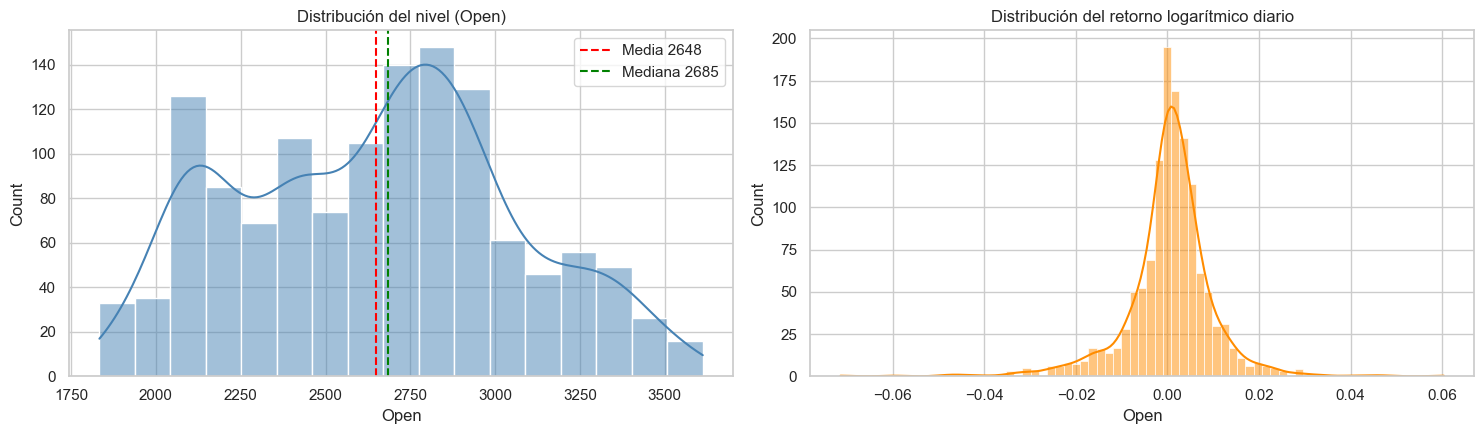

Estadísticas del retorno logarítmico diario:
media_diaria_%               0.041
desv_diaria_%                0.967
volatilidad_anualizada_%    15.348
asimetria                   -0.805
curtosis_exceso              7.855
min_%                       -7.141
max_%                        6.034

Jarque-Bera (normalidad del retorno): estadístico=3493.1, p-valor=0.00e+00

Mayores caídas diarias:
Date
2020-03-12   -7.14
2020-03-23   -5.98
2020-02-28   -4.87
2018-02-06   -4.72
2020-04-01   -4.56


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(serie, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(serie.mean(), color="red", ls="--", label=f"Media {serie.mean():.0f}")
axes[0].axvline(serie.median(), color="green", ls="--", label=f"Mediana {serie.median():.0f}")
axes[0].set_title("Distribución del nivel (Open)")
axes[0].legend()
sns.histplot(ret, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Distribución del retorno logarítmico diario")
plt.tight_layout()
plt.show()

print("Estadísticas del retorno logarítmico diario:")
print(pd.Series({
    "media_diaria_%": ret.mean() * 100,
    "desv_diaria_%": ret.std() * 100,
    "volatilidad_anualizada_%": ret.std() * np.sqrt(252) * 100,
    "asimetria": stats.skew(ret),
    "curtosis_exceso": stats.kurtosis(ret),
    "min_%": ret.min() * 100,
    "max_%": ret.max() * 100,
}).round(3).to_string())
jb = stats.jarque_bera(ret)
print(f"\nJarque-Bera (normalidad del retorno): estadístico={jb.statistic:.1f}, p-valor={jb.pvalue:.2e}")
print("\nMayores caídas diarias:")
print((ret.nsmallest(5) * 100).round(2).to_string())

**Conclusiones**

*Sobre el nivel del precio*
- Media 2 648,25 y mediana 2 685,49: son cercanas (la diferencia es 1,4 %), y la asimetría es casi nula (0,09). **Pero esto no significa que no haya atípicos ni que la serie sea "estable"**: la media y la desviación estándar de un nivel con tendencia **no son parámetros estables**, ya que dependen de en qué tramo del tiempo se calcule. Un coeficiente de variación de 15,4 % (desv. 408 sobre media 2 648) refleja sobre todo la tendencia.
- La curtosis negativa (-0,76) y el histograma achatado y casi bimodal tampoco indican una distribución "normal"; son consecuencia de que el precio recorrió rangos distintos en periodos distintos.
- El rango (1 833 a 3 612) muestra que el índice casi se duplica en cinco años.

*Sobre los retornos (donde sí tiene sentido interpretar la distribución)*
- Retorno medio diario de 0,041 % (≈ 10 % anual) con desviación de 0,97 % (**volatilidad anualizada ≈ 15,3 %**).
- **Colas pesadas:** curtosis en exceso de 7,9 (una normal tendría 0) y asimetría negativa (-0,81): las caídas grandes son más frecuentes y más fuertes que las subidas. La prueba de Jarque-Bera rechaza la normalidad con contundencia.
- Los eventos extremos se concentran en 2020: el 12-mar-2020 el índice abrió 7,1 % por debajo de la apertura del día previo (retorno logarítmico), y 11 días superan 4 desviaciones estándar, cuando bajo normalidad serían esperables menos de uno.
- **Implicación para el modelado:** los residuos de cualquier modelo no serán normales ni de varianza constante, así que los intervalos de confianza "teóricos" serán demasiado optimistas (se verifica en la sección 5).


## 3. Preparación de los datos

Los pasos aplicados y su justificación:

| Paso | Acción | Justificación |
|---|---|---|
| 1. Selección de la variable | Se conserva solo `Open` | Serie univariada; ver 2.2 |
| 2. Conversión de tipos | `Date` → `datetime64` e índice; `Open` → `float` | Los modelos de `statsmodels` requieren un índice temporal con frecuencia |
| 3. Corrección de calendario | Eliminación de sábados y domingos y frecuencia `B` | Los fines de semana eran copias del viernes (ver 2.2) |
| 4. Datos faltantes | Revisión de nulos | La base no tiene nulos, y tras filtrar tampoco aparecen huecos al aplicar `asfreq("B")`; **no se imputa nada** |
| 5. Atípicos | Se identifican (|z| > 4) pero **no se eliminan** | Son eventos reales (COVID-19), no errores de captura; eliminarlos haría que el modelo ignorara el riesgo real |
| 6. Transformación | Diferenciación y retornos logarítmicos | Se justifican con las pruebas de estacionariedad que siguen |
| 7. Partición temporal | Desarrollo / evaluación sin barajar | Evita fuga de información del futuro hacia el pasado |


In [ ]:
# 3.1 Resumen de calidad de la serie de trabajo
print("Tipo de dato de la variable:", serie.dtypes)
print("Tipo de índice:", type(serie.index).__name__, "| frecuencia:", serie.index.freqstr)
print("Nulos:", serie.isna().sum(), "| ceros o negativos:", int((serie <= 0).sum()))
print("Índice ordenado y sin duplicados:", serie.index.is_monotonic_increasing and serie.index.is_unique)

# 3.2 Valores atípicos en el retorno (regla de 4 desviaciones; solo se identifican, no se eliminan)
z = (ret - ret.mean()) / ret.std()
print("\nDías con |z|>4 en el retorno:", int((z.abs() > 4).sum()))
print((ret[z.abs() > 4] * 100).round(2).to_string())

Tipo de dato de la variable: float64
Tipo de índice: DatetimeIndex | frecuencia: B
Nulos: 0 | ceros o negativos: 0
Índice ordenado y sin duplicados: True

Días con |z|>4 en el retorno: 11
Date
2018-02-06   -4.72
2018-12-06   -4.37
2020-02-28   -4.87
2020-03-03    4.03
2020-03-06   -4.03
2020-03-12   -7.14
2020-03-23   -5.98
2020-03-25    4.72
2020-04-01   -4.56
2020-04-07    6.03
2020-06-16    4.48


**Atípicos.** Hay 11 días con retornos de más de 4 desviaciones estándar: 9 en 2020 (7 de ellos entre marzo y abril) y 2 en 2018. Todos corresponden a hechos conocidos (corrección de feb-2018, caída de dic-2018, pánico y rebote de COVID-19). Son datos válidos y se conservan.


In [ ]:
# 3.3 Pruebas de estacionariedad: ADF (H0: raíz unitaria) y KPSS (H0: estacionaria)
def pruebas_estacionariedad(s, nombre):
    s = s.dropna()
    adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    return {"serie": nombre, "ADF_stat": adf_stat, "ADF_p": adf_p, "KPSS_stat": kpss_stat, "KPSS_p": kpss_p,
            "veredicto": "estacionaria" if (adf_p < 0.05 and kpss_p >= 0.05) else "NO estacionaria"}

tabla_est = pd.DataFrame([
    pruebas_estacionariedad(serie, "Open (nivel)"),
    pruebas_estacionariedad(serie.diff(), "Open diferenciada (d=1)"),
    pruebas_estacionariedad(serie.diff().diff(), "Open diferenciada (d=2)"),
    pruebas_estacionariedad(ret, "Retorno log. diario"),
]).set_index("serie")
tabla_est.round(4)

,ADF_stat,ADF_p,KPSS_stat,KPSS_p,veredicto
serie,,,,,
Open (nivel),-0.9685,0.7646,5.3489,0.01,NO estacionaria
Open diferenciada (d=1),-10.5845,0.0000,0.0544,0.10,estacionaria
Open diferenciada (d=2),-12.2592,0.0000,0.0360,0.10,estacionaria
Retorno log. diario,-12.3816,0.0000,0.0358,0.10,estacionaria


**Estacionariedad: ADF y KPSS.** Se usan dos pruebas con hipótesis nulas opuestas, lo que da más confianza que una sola:

- **ADF:** H0 = hay raíz unitaria (no estacionaria). Estacionaria si p < 0,05.
- **KPSS:** H0 = la serie es estacionaria. Estacionaria si p ≥ 0,05.

**Resultados:**
- **Nivel de `Open`:** ADF p = 0,76 (no se rechaza raíz unitaria) y KPSS p = 0,01 (se rechaza estacionariedad). Ambas coinciden: **no es estacionaria**, así que hay que diferenciar.
- **Primera diferencia (d = 1):** ADF p ≈ 0 y KPSS p ≥ 0,10: **estacionaria**.
- **Segunda diferencia (d = 2):** también pasa las pruebas, pero eso **no significa que haya que usarla**. Diferenciar de más (*sobrediferenciación*) introduce autocorrelación negativa artificial y aumenta la varianza.
- **Retorno logarítmico:** estacionario.

**Conclusión:** el orden de integración es **d = 1**. Esto corrige el modelo anterior, que usaba ARIMA(3, **2**, 1) pese a que en la búsqueda de órdenes había fijado `d=1` y la propia prueba ADF indicaba que con una diferencia basta.


In [ ]:
# 3.4 Partición temporal. Se evaluará con ventanas móviles sobre los últimos N_EVAL días hábiles;
# todo lo que se decide (orden de ARIMA, hiperparámetros de SVR) se decide SOLO con datos anteriores.
H = 20            # horizonte de pronóstico: 20 días hábiles (~1 mes)
N_VENT = 12       # número de ventanas de evaluación
N_EVAL = H * N_VENT   # 240 días hábiles (~1 año)

serie_dev = serie.iloc[:-N_EVAL]     # desarrollo: selección de orden e hiperparámetros
serie_eval = serie.iloc[-N_EVAL:]    # evaluación (ventanas móviles)
print(f"Desarrollo : {serie_dev.index[0].date()} -> {serie_dev.index[-1].date()}  ({len(serie_dev)} obs)")
print(f"Evaluación : {serie_eval.index[0].date()} -> {serie_eval.index[-1].date()}  ({len(serie_eval)} obs, {N_VENT} ventanas de {H} días)")

Desarrollo : 2015-11-23 -> 2019-12-20  (1065 obs)
Evaluación : 2019-12-23 -> 2020-11-20  (240 obs, 12 ventanas de 20 días)


**Partición temporal y por qué esa ventana de pronóstico.**

- **Horizonte de pronóstico: 20 días hábiles (≈ 1 mes bursátil).** Es un plazo con sentido práctico (rebalanceo mensual de portafolios) y estadísticamente defendible: en series con comportamiento de caminata aleatoria la incertidumbre crece con la raíz del horizonte, y más allá de unas semanas el intervalo se vuelve tan ancho que el pronóstico deja de ser informativo. Un horizonte de 325 días (como en la versión anterior) produce una línea casi recta sin valor predictivo.
- **Evaluación con 12 ventanas móviles de 20 días (240 días hábiles ≈ 1 año, de dic-2019 a nov-2020).** Una sola partición es frágil, porque su resultado depende de en qué momento cae. Con ventanas móviles el modelo se **re-ajusta en cada origen** con todos los datos disponibles hasta ese punto, tal como se haría en la práctica, y se promedia el error sobre 240 pronósticos. Además, el año de evaluación incluye tanto un periodo calmado (ene-2020) como el desplome de COVID-19 y la recuperación, lo que hace la prueba exigente.
- **Sin fuga de información:** el orden del ARIMA y los hiperparámetros del SVR se eligen **solo con el tramo de desarrollo** (hasta 2019-12-20). Nada del año de evaluación influye en esas decisiones.


## 4. Modelado y predicción

Se comparan tres enfoques:

1. **ARIMA** (`statsmodels`): modelo estadístico clásico, interpretable y que entrega intervalos de confianza.
2. **SVR** (`scikit-learn`): modelo no paramétrico de aprendizaje automático, para contrastar con un enfoque distinto.
3. **Caminata aleatoria (naive):** "el precio de mañana es el de hoy". No es un modelo que se *ajuste*, sino la **vara de medir**: cualquier modelo que no la supere no aporta valor.

### 4.1 ARIMA


**Selección del orden (p, d, q).**

- **d = 1**, según las pruebas ADF/KPSS de la sección 3.
- **p y q** se buscan en la rejilla 0-3 comparando **AIC** y **BIC** sobre los datos de desarrollo. Ambos miden ajuste con penalización por complejidad; el BIC penaliza más y favorece modelos simples.
- Se incluye **deriva (`trend="t"`)**: la serie diferenciada tiene media positiva (≈ 1,1 puntos por día), y sin ese término los pronósticos serían una línea horizontal, ignorando el crecimiento histórico.
- La rejilla se calcula con `d = 1` fijo; comparar AIC/BIC entre distintos `d` no es válido porque las series diferenciadas son distintas.


In [ ]:
def comparar_ordenes(s, rango_p, rango_q, d=1):
    filas = []
    for p, q in itertools.product(rango_p, rango_q):
        try:
            m = ARIMA(s, order=(p, d, q), trend="t").fit()   # trend="t": deriva (drift) lineal sobre la serie original
            filas.append({"p": p, "d": d, "q": q, "AIC": m.aic, "BIC": m.bic})
        except Exception:
            continue
    return pd.DataFrame(filas)

grid = comparar_ordenes(serie_dev, range(0, 4), range(0, 4), d=1)
print("Top 5 por AIC:")
display(grid.sort_values("AIC").head(5).round(2).reset_index(drop=True))
print("Top 5 por BIC:")
display(grid.sort_values("BIC").head(5).round(2).reset_index(drop=True))

Top 5 por AIC:


,p,d,q,AIC,BIC
0,2,1,2,9287.84,9317.66
1,0,1,0,9290.63,9300.57
2,3,1,2,9290.71,9325.50
3,2,1,3,9290.72,9325.51
4,3,1,3,9291.56,9331.32


Top 5 por BIC:


,p,d,q,AIC,BIC
0,0,1,0,9290.63,9300.57
1,1,1,0,9292.58,9307.49
2,0,1,1,9292.58,9307.49
3,2,1,0,9294.50,9314.38
4,0,1,2,9294.50,9314.38


**Lectura de la rejilla y decisión.**

- El **AIC** más bajo corresponde a ARIMA(2,1,2), pero su ventaja sobre el ARIMA(0,1,0) es de solo ~2,8 puntos. Además, los coeficientes revelan un problema: ar.L2 (-0,96) y ma.L2 (+0,99) están casi en el límite de no estacionariedad/no invertibilidad y se cancelan entre sí, síntoma clásico de **sobreajuste** (el modelo está ajustando ruido).
- El **BIC** elige ARIMA(0,1,0) con un margen amplio, y es coherente con lo visto en el ACF/PACF de la serie diferenciada, que no mostraba estructura.
- **Decisión: ARIMA(0,1,0) con deriva como modelo principal**, por el *principio de parsimonia* (entre modelos con ajuste equivalente se prefiere el más simple). El ARIMA(2,1,2) se conserva solo como **contraste**, para comprobar empíricamente que la mayor complejidad no mejora la predicción.
- Interpretación: ARIMA(0,1,0) con deriva es una **caminata aleatoria con tendencia** ($P_t = P_{t-1} + \mu + \varepsilon_t$), lo cual coincide con la hipótesis de mercados eficientes en su forma débil. La deriva estimada es ≈ 1,07 puntos/día con p = 0,08, o sea, **no es estadísticamente significativa al 5 %**; se mantiene porque la tendencia histórica es evidente, pero con cautela.


In [ ]:
elegir = lambda criterio: tuple(int(x) for x in grid.sort_values(criterio).iloc[0][["p", "d", "q"]])
ORDEN = elegir("BIC")          # modelo principal: criterio parsimonioso
ORDEN_AIC = elegir("AIC")      # alternativa más compleja, se evalúa como contraste
print("Orden por BIC (modelo principal):", ORDEN, "| orden por AIC (contraste):", ORDEN_AIC)

modelo_dev = ARIMA(serie_dev, order=ORDEN, trend="t").fit()
print(modelo_dev.summary())

print("\nModelo de contraste (AIC):")
print(ARIMA(serie_dev, order=ORDEN_AIC, trend="t").fit().summary().tables[1])

Orden por BIC (modelo principal): (0, 1, 0) | orden por AIC (contraste): (2, 1, 2)


                               SARIMAX Results                                
Dep. Variable:                   Open   No. Observations:                 1065
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -4643.315
Date:                Sun, 25 Oct 2026   AIC                           9290.630
Time:                        08:28:03   BIC                           9300.570
Sample:                    11-23-2015   HQIC                          9294.397
                         - 12-20-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             1.0657      0.612      1.741      0.082      -0.134       2.265
sigma2       361.4093      8.322     43.426      0.000     345.098     377.721
Ljung-Box (L1) (Q):                   0.05   Jarque-

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             1.0715      0.621      1.726      0.084      -0.145       2.288
ar.L1          0.5463      0.013     40.530      0.000       0.520       0.573
ar.L2         -0.9608      0.013    -76.151      0.000      -0.986      -0.936
ma.L1         -0.5516      0.008    -69.749      0.000      -0.567      -0.536
ma.L2          0.9895      0.007    145.270      0.000       0.976       1.003
sigma2       357.5318      8.218     43.505      0.000     341.425     373.639


### 4.2 Pronóstico por ventanas móviles

Para cada uno de los 12 orígenes se ajusta cada modelo con el histórico disponible y se pronostican los siguientes 20 días hábiles. Así se obtienen 240 pronósticos fuera de muestra por modelo, con los que se calculan las métricas de la sección 5.


In [ ]:
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    return {"MAE": mean_absolute_error(real, pred),
            "RMSE": np.sqrt(mean_squared_error(real, pred)),
            "MAPE_%": np.mean(np.abs((real - pred) / real)) * 100}

origenes = list(range(len(serie) - N_EVAL, len(serie), H))   # posiciones donde "empieza" cada pronóstico

# ---- ARIMA: se re-ajusta con todo el histórico disponible en cada origen ----
def rolling_arima(orden):
    medias, inf, sup = [], [], []
    for o in origenes:
        pron = ARIMA(serie.iloc[:o], order=orden, trend="t").fit().get_forecast(H)
        medias.append(pron.predicted_mean)
        ci = pron.conf_int(alpha=0.05)
        inf.append(ci.iloc[:, 0]); sup.append(ci.iloc[:, 1])
    return pd.concat(medias), pd.concat(inf), pd.concat(sup)

pred_arima, ic_inf, ic_sup = rolling_arima(ORDEN)                 # modelo principal (BIC)
pred_arima_aic, ic_inf_aic, ic_sup_aic = rolling_arima(ORDEN_AIC) # contraste (AIC)

# ---- Referencia: caminata aleatoria (el último valor observado se repite H días) ----
pred_naive = pd.concat([pd.Series(serie.iloc[o - 1], index=serie.index[o:o + H]) for o in origenes])

real = serie.loc[pred_arima.index]
print("Pronósticos generados:", len(pred_arima), "| ventanas:", len(origenes))

Pronósticos generados: 240 | ventanas: 12


### 4.3 Support Vector Regression (SVR)

**Por qué y cómo.** El SVR no entiende el tiempo; hay que convertir la serie en un problema supervisado con *rezagos* (*lags*). Diferencias con la versión anterior y su justificación:

| Decisión | Motivo |
|---|---|
| **Se modelan los retornos logarítmicos, no el precio** | Un SVR con kernel RBF no puede extrapolar fuera del rango visto en entrenamiento: si el precio de prueba (3 600) supera el máximo de entrenamiento (~3 220), el modelo "se queda corto" y la predicción se aplana. Los retornos son estacionarios y viven siempre en el mismo rango. El precio se reconstruye acumulando los retornos pronosticados. |
| **5 rezagos** | Una semana bursátil de historia; la PACF no sugiere dependencia más larga. |
| **`StandardScaler` ajustado solo con entrenamiento** | Evita fuga de información; los retornos tienen colas pesadas y el estandarizado es menos sensible a ellas que el Min-Max. |
| **Hiperparámetros por `GridSearchCV` con `TimeSeriesSplit`** | Antes se fijaron a mano (`C=100`). La validación cruzada temporal respeta el orden cronológico y se hace solo con el tramo de desarrollo. |
| **Pronóstico recursivo a 20 días** | Para que la comparación con ARIMA sea justa. Antes el SVR predecía un solo día usando valores *reales* de los días previos, mientras ARIMA proyectaba 325 días a ciegas: eran dos tareas de dificultad muy distinta. |


In [ ]:
N_LAGS = 5

def crear_lags(r, n_lags=N_LAGS):
    """Matriz supervisada: retorno(t) ~ retornos(t-1 ... t-n_lags)."""
    X = pd.concat({f"lag_{i}": r.shift(i) for i in range(1, n_lags + 1)}, axis=1)
    return X.dropna(), r.loc[X.dropna().index]

# Búsqueda de hiperparámetros SOLO con datos de desarrollo y validación cruzada temporal
ret_dev = np.log(serie_dev).diff().dropna()
X_dev, y_dev = crear_lags(ret_dev)
pipe_scaler = StandardScaler().fit(X_dev)

busqueda = GridSearchCV(
    SVR(kernel="rbf"),
    param_grid={"C": [0.1, 1, 10], "epsilon": [0.01, 0.1, 0.5], "gamma": ["scale", 0.01, 0.1]},
    cv=TimeSeriesSplit(n_splits=5), scoring="neg_mean_squared_error", n_jobs=1,
)
y_std = (y_dev - y_dev.mean()) / y_dev.std()
busqueda.fit(pipe_scaler.transform(X_dev), y_std)
PARAMS_SVR = busqueda.best_params_
print("Mejores hiperparámetros SVR:", PARAMS_SVR)

def pronostico_svr(hist, h=H):
    """Re-entrena con 'hist' y pronostica h pasos de forma recursiva (usa sus propias predicciones como lags)."""
    r = np.log(hist).diff().dropna()
    X, y = crear_lags(r)
    sc = StandardScaler().fit(X)
    mu, sd = y.mean(), y.std()
    modelo = SVR(kernel="rbf", **PARAMS_SVR).fit(sc.transform(X), (y - mu) / sd)
    ultimos = list(r.iloc[-N_LAGS:].values)          # del más antiguo al más reciente
    precio, salida = hist.iloc[-1], []
    for _ in range(h):
        x = np.array(ultimos[::-1][:N_LAGS]).reshape(1, -1)   # lag_1 = retorno más reciente
        r_hat = modelo.predict(sc.transform(pd.DataFrame(x, columns=X.columns)))[0] * sd + mu
        precio = precio * np.exp(r_hat)
        salida.append(precio)
        ultimos.append(r_hat)
    idx = pd.date_range(hist.index[-1] + pd.offsets.BDay(1), periods=h, freq="B")
    return pd.Series(salida, index=idx)

pred_svr = pd.concat([pronostico_svr(serie.iloc[:o]) for o in origenes])
print("Pronósticos SVR:", len(pred_svr))

Mejores hiperparámetros SVR: {'C': 0.1, 'epsilon': 0.1, 'gamma': 0.01}


Pronósticos SVR: 240


### 4.4 Pronóstico a futuro

Con el modelo principal ya validado, se **re-ajusta con todos los datos disponibles** (hasta el 2020-11-20) y se pronostican los próximos 20 días hábiles, con intervalo de confianza del 95 %. Antes se etiquetaba esta salida como "meses", pero la serie es diaria; aquí se expresa correctamente en días hábiles.


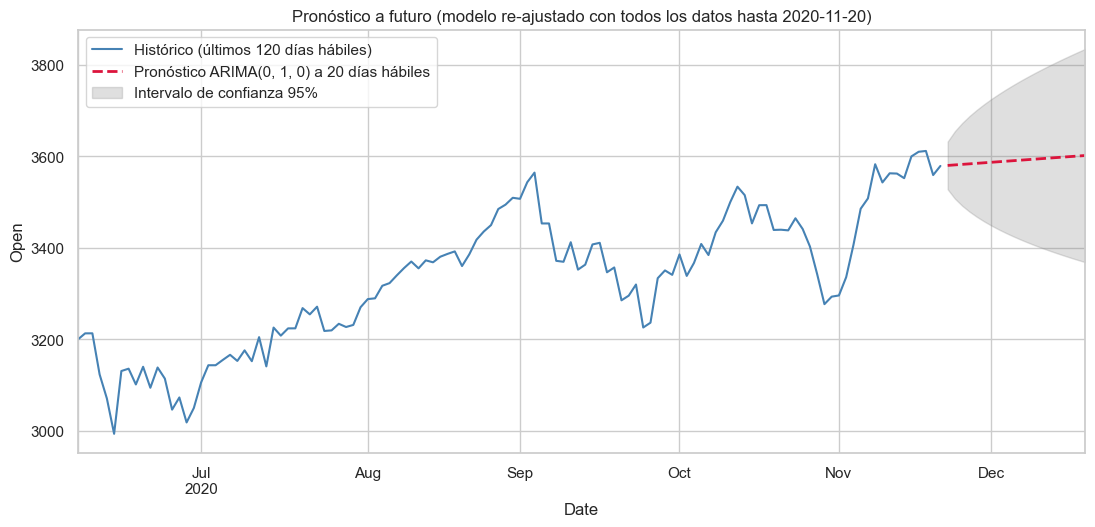

,pronostico,limite_inf_95,limite_sup_95
2020-11-23,3580.45,3528.30,3632.61
2020-11-24,3581.60,3507.84,3655.35
2020-11-25,3582.74,3492.40,3673.07
2020-11-26,3583.88,3479.57,3688.19
2020-11-27,3585.02,3468.40,3701.65
2020-11-30,3586.17,3458.41,3713.92
2020-12-01,3587.31,3449.32,3725.30
2020-12-02,3588.45,3440.93,3735.97
2020-12-03,3589.59,3433.13,3746.06
2020-12-04,3590.74,3425.81,3755.66


In [ ]:
modelo_final = ARIMA(serie, order=ORDEN, trend="t").fit()
fut = modelo_final.get_forecast(H)
media_fut = fut.predicted_mean
ic_fut = fut.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(13, 5.5))
serie.iloc[-120:].plot(ax=ax, label="Histórico (últimos 120 días hábiles)", color="steelblue")
media_fut.plot(ax=ax, style="--", color="crimson", lw=2, label=f"Pronóstico ARIMA{ORDEN} a {H} días hábiles")
ax.fill_between(ic_fut.index, ic_fut.iloc[:, 0], ic_fut.iloc[:, 1], color="gray", alpha=0.25, label="Intervalo de confianza 95%")
ax.set_title(f"Pronóstico a futuro (modelo re-ajustado con todos los datos hasta {serie.index[-1].date()})")
ax.set_ylabel("Open")
ax.legend(loc="upper left")
plt.show()

salida_fut = pd.concat([media_fut.rename("pronostico"), ic_fut], axis=1)
salida_fut.columns = ["pronostico", "limite_inf_95", "limite_sup_95"]
salida_fut.round(2).head(10)

**Lectura del pronóstico a futuro.**
- El pronóstico central sube lentamente (de ~3 580 a ~3 590 en 10 días hábiles) porque solo refleja la deriva estimada. **No es una predicción de que el índice subirá ese valor**, sino la expectativa condicional de un modelo sin otra información.
- El intervalo se ensancha con el horizonte: a 1 día es de ±52 puntos y a 10 días, de ±165. Este crecimiento es la forma honesta de expresar que **la incertidumbre aumenta con el plazo**.
- Como se verá en la sección 5, este intervalo es **optimista** (cubre solo ~80 % en lugar de 95 %), así que la verdadera incertidumbre es mayor.


## 5. Evaluación

### 5.1 Métricas

Se usan cuatro medidas, cada una con un propósito:

| Métrica | Qué mide | Cómo interpretarla |
|---|---|---|
| **MAE** | Error absoluto medio, en puntos del índice | Fácil de leer: "en promedio nos equivocamos en X puntos" |
| **RMSE** | Raíz del error cuadrático medio | Penaliza más los errores grandes, útil para ver el efecto de eventos extremos |
| **MAPE** | Error porcentual medio | Comparable entre niveles de precio |
| **MASE vs. naive** | MAE del modelo ÷ MAE de la caminata aleatoria | **< 1 = mejora a la referencia; > 1 = peor.** Es la métrica clave para saber si el modelo aporta |

Adicionalmente se mide la **cobertura del intervalo de confianza** (qué fracción de los valores reales cae dentro del intervalo del 95 %), que debería ser cercana a 95 %.


In [ ]:
resultados = pd.DataFrame({
    f"ARIMA{ORDEN}+drift (BIC, principal)": metricas(real, pred_arima),
    f"ARIMA{ORDEN_AIC}+drift (AIC, contraste)": metricas(real, pred_arima_aic),
    "SVR (rbf, retornos)": metricas(real, pred_svr.loc[real.index]),
    "Caminata aleatoria (naive)": metricas(real, pred_naive.loc[real.index]),
}).T
resultados["MASE_vs_naive"] = resultados["MAE"] / resultados.loc["Caminata aleatoria (naive)", "MAE"]
display(resultados.round(3))

cobertura = ((real >= ic_inf) & (real <= ic_sup)).mean()
cobertura_aic = ((real >= ic_inf_aic) & (real <= ic_sup_aic)).mean()
print(f"Cobertura empírica del IC 95% -> ARIMA{ORDEN}: {cobertura:.1%} | ARIMA{ORDEN_AIC}: {cobertura_aic:.1%} (ideal: 95%)")

,MAE,RMSE,MAPE_%,MASE_vs_naive
"ARIMA(0, 1, 0)+drift (BIC, principal)",107.378,159.028,3.492,0.981
"ARIMA(2, 1, 2)+drift (AIC, contraste)",108.829,162.185,3.533,0.994
"SVR (rbf, retornos)",102.720,159.271,3.359,0.939
Caminata aleatoria (naive),109.433,158.173,3.549,1.000


Cobertura empírica del IC 95% -> ARIMA(0, 1, 0): 79.6% | ARIMA(2, 1, 2): 80.0% (ideal: 95%)


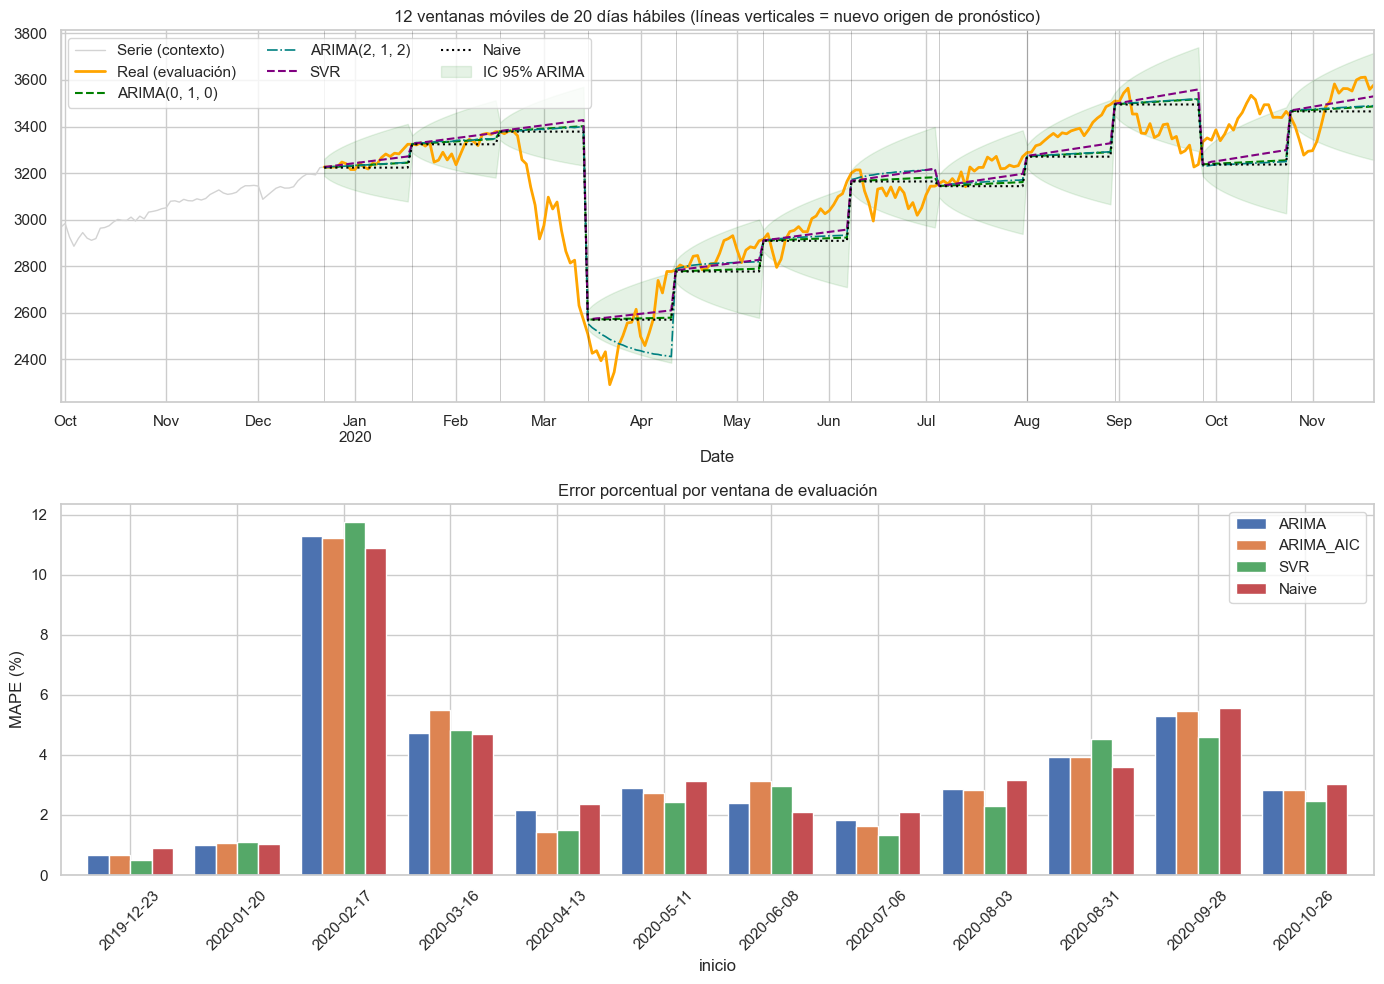

,ARIMA,ARIMA_AIC,SVR,Naive
inicio,,,,
2019-12-23,0.66,0.65,0.50,0.89
2020-01-20,1.01,1.05,1.11,1.02
2020-02-17,11.30,11.23,11.77,10.89
2020-03-16,4.71,5.48,4.82,4.70
2020-04-13,2.15,1.43,1.50,2.37
2020-05-11,2.91,2.73,2.43,3.13
2020-06-08,2.39,3.13,2.97,2.10
2020-07-06,1.84,1.63,1.34,2.11
2020-08-03,2.88,2.83,2.29,3.18


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

serie.iloc[-N_EVAL - 60:].plot(ax=axes[0], color="lightgray", lw=1, label="Serie (contexto)")
real.plot(ax=axes[0], color="orange", lw=2, label="Real (evaluación)")
pred_arima.plot(ax=axes[0], style="--", color="green", lw=1.5, label=f"ARIMA{ORDEN}")
pred_arima_aic.plot(ax=axes[0], style="-.", color="teal", lw=1.2, label=f"ARIMA{ORDEN_AIC}")
pred_svr.loc[real.index].plot(ax=axes[0], style="--", color="purple", lw=1.5, label="SVR")
pred_naive.loc[real.index].plot(ax=axes[0], style=":", color="black", lw=1.5, label="Naive")
axes[0].fill_between(ic_inf.index, ic_inf, ic_sup, color="green", alpha=0.10, label="IC 95% ARIMA")
for o in origenes:
    axes[0].axvline(serie.index[o], color="k", lw=0.4, alpha=0.4)
axes[0].set_title(f"{N_VENT} ventanas móviles de {H} días hábiles (líneas verticales = nuevo origen de pronóstico)")
axes[0].legend(loc="upper left", ncol=3)

# Error porcentual medio por ventana
tabla_vent = pd.DataFrame({
    "inicio": [serie.index[o].date() for o in origenes],
    "ARIMA": [metricas(serie.iloc[o:o + H], pred_arima.iloc[i * H:(i + 1) * H])["MAPE_%"] for i, o in enumerate(origenes)],
    "ARIMA_AIC": [metricas(serie.iloc[o:o + H], pred_arima_aic.iloc[i * H:(i + 1) * H])["MAPE_%"] for i, o in enumerate(origenes)],
    "SVR": [metricas(serie.iloc[o:o + H], pred_svr.loc[serie.index[o:o + H]])["MAPE_%"] for o in origenes],
    "Naive": [metricas(serie.iloc[o:o + H], pred_naive.loc[serie.index[o:o + H]])["MAPE_%"] for o in origenes],
}).set_index("inicio")
tabla_vent.plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_ylabel("MAPE (%)")
axes[1].set_title("Error porcentual por ventana de evaluación")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
tabla_vent.round(2)

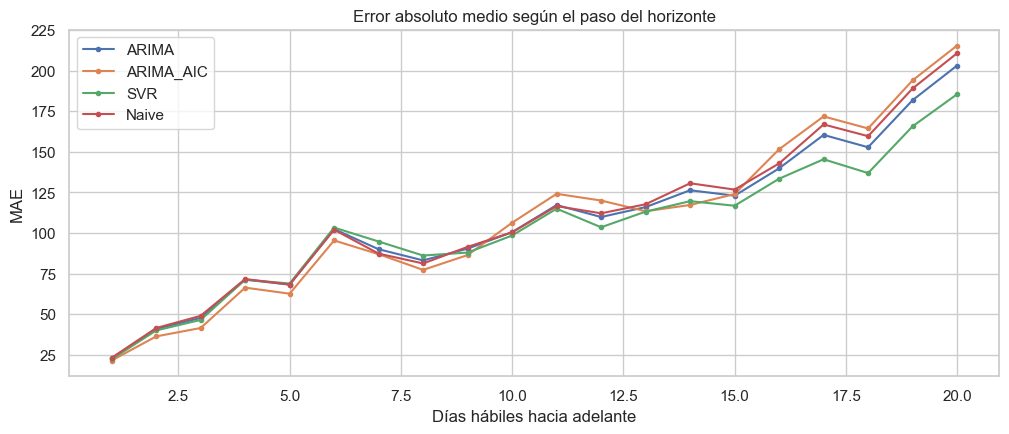

In [ ]:
# Error según el paso del horizonte (1 = mañana, 20 = dentro de ~1 mes)
pasos = np.tile(np.arange(1, H + 1), N_VENT)
err = pd.DataFrame({
    "paso": pasos,
    "ARIMA": np.abs(real.values - pred_arima.values),
    "ARIMA_AIC": np.abs(real.values - pred_arima_aic.values),
    "SVR": np.abs(real.values - pred_svr.loc[real.index].values),
    "Naive": np.abs(real.values - pred_naive.loc[real.index].values),
}).groupby("paso").mean()
ax = err.plot(figsize=(12, 4.5), marker="o", ms=3)
ax.set_title("Error absoluto medio según el paso del horizonte")
ax.set_xlabel("Días hábiles hacia adelante")
ax.set_ylabel("MAE")
plt.show()

### 5.2 Interpretación de resultados

**Comparación de modelos (240 pronósticos fuera de muestra a 20 días):**

| Modelo | MAE | RMSE | MAPE | MASE vs naive |
|---|---|---|---|---|
| ARIMA(0,1,0) + deriva (principal) | 107,4 | 159,0 | 3,49 % | 0,98 |
| ARIMA(2,1,2) + deriva (contraste) | 108,8 | 162,2 | 3,53 % | 0,99 |
| SVR (retornos) | 102,7 | 159,3 | 3,36 % | 0,94 |
| Caminata aleatoria (referencia) | 109,4 | 158,2 | 3,55 % | 1,00 |

1. **Ningún modelo supera claramente a la referencia.** Las diferencias en MAE son del 2 % (ARIMA) al 6 % (SVR), y el RMSE del naive es incluso el menor. Con 12 ventanas que se solapan en régimen de mercado, diferencias de ese tamaño **no son estadísticamente concluyentes**. El resultado es consistente con la hipótesis de mercado eficiente: el precio pasado contiene poca información explotable sobre el precio futuro.
2. **El modelo complejo no ayudó.** ARIMA(2,1,2) rinde igual o peor que ARIMA(0,1,0), lo que confirma que la elección parsimoniosa por BIC era correcta y que el menor AIC era sobreajuste.
3. **El SVR queda ligeramente por delante en MAE y MAPE,** pero no en RMSE, de modo que su ventaja se da en días normales y no en los extremos. Una explicación posible (no verificada aquí) es que sus pronósticos son casi planos y por eso se parecen al naive. Se reporta el hallazgo con cautela.
4. **El error depende del régimen de mercado, mucho más que del modelo.** El MAPE por ventana va de ~0,5-1 % en periodos calmados a **~11 % en la ventana de febrero-2020**, con los tres modelos fallando por igual: ningún modelo basado en el pasado anticipa un desplome provocado por un evento externo.
5. **El error crece con el horizonte** (gráfico por paso): casi nulo a 1 día y creciente hasta 20 días, como corresponde a una serie con raíz unitaria.
6. **Intervalos demasiado estrechos:** la cobertura real es ≈ 80 % frente al 95 % nominal. El modelo supone varianza constante, y la de 2020 fue muy superior a la de 2016-2019.


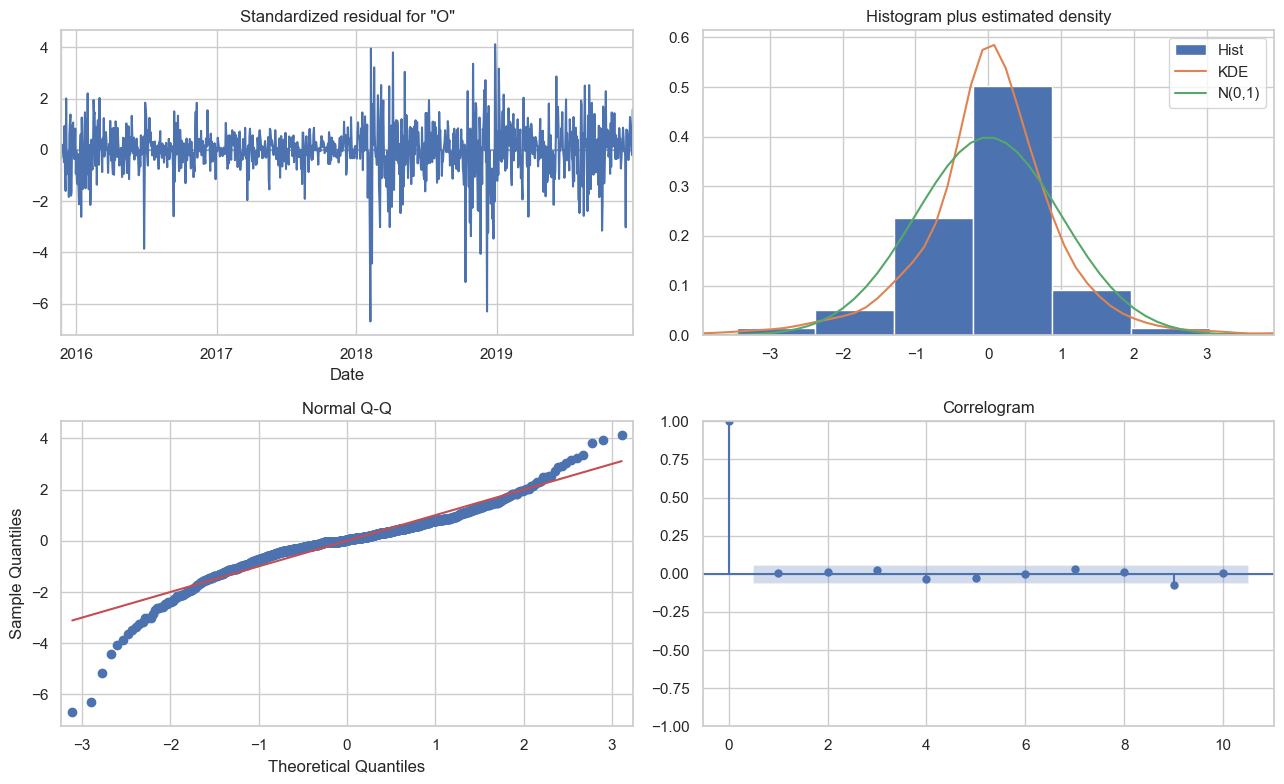

Ljung-Box (H0: residuos sin autocorrelación):


,lb_stat,lb_pvalue
10,10.1028,0.4315
20,19.5424,0.4869
40,39.3648,0.4987


ARCH-LM (H0: varianza constante): estadístico=101.2, p-valor=3.13e-17
Jarque-Bera (H0: residuos normales): estadístico=1628.1, p-valor=0.00e+00


In [ ]:
# Diagnóstico de residuos del modelo ARIMA ajustado con los datos de desarrollo (se omite el primer residuo, artefacto de inicialización)
res = modelo_dev.resid.iloc[1:]
modelo_dev.plot_diagnostics(figsize=(13, 8))
plt.tight_layout()
plt.show()

lb = acorr_ljungbox(res, lags=[10, 20, 40], return_df=True)
arch_stat, arch_p, _, _ = het_arch(res, nlags=10)
jb_res = stats.jarque_bera(res)
print("Ljung-Box (H0: residuos sin autocorrelación):")
display(lb.round(4))
print(f"ARCH-LM (H0: varianza constante): estadístico={arch_stat:.1f}, p-valor={arch_p:.2e}")
print(f"Jarque-Bera (H0: residuos normales): estadístico={jb_res.statistic:.1f}, p-valor={jb_res.pvalue:.2e}")

### 5.3 Diagnóstico de residuos

Si el modelo capturó toda la estructura lineal, sus residuos deben parecerse a ruido blanco: sin autocorrelación, de varianza constante y aproximadamente normales.

| Supuesto | Prueba | Resultado | Veredicto |
|---|---|---|---|
| Sin autocorrelación | Ljung-Box (rezagos 10, 20, 40) | p entre 0,43 y 0,50 | **Se cumple.** No queda dependencia lineal sin modelar |
| Varianza constante | ARCH-LM | p ≈ 3·10⁻¹⁷ | **No se cumple.** Hay *clusters* de volatilidad |
| Normalidad | Jarque-Bera, Q-Q | p ≈ 0; curtosis ≈ 8,8 | **No se cumple.** Colas muy pesadas |

**Conclusión:** el ARIMA extrajo toda la dependencia lineal que había (la media está bien modelada), pero la **varianza** no, y la distribución de los errores tiene colas pesadas. Por eso los puntos centrales son aceptables como referencia y los intervalos de confianza no son confiables.


### 5.4 Limitaciones y posibles mejoras

**Limitaciones**
- **Poca estructura predecible.** Es una limitación de los datos y no del modelo: la serie diferenciada se comporta como ruido blanco, de modo que ningún modelo univariado de precios pasados puede ganarle mucho a "mañana = hoy".
- **Varianza no constante y colas pesadas** (ARCH-LM y Jarque-Bera): intervalos subestimados (cobertura ≈ 80 %).
- **Un solo ciclo de crisis** en el periodo de evaluación. 12 ventanas solapadas dan una evidencia limitada y concentrada en una situación atípica (COVID-19).
- **Festivos** (47 días) tratados como días normales con valor repetido.
- **Deriva no significativa** (p = 0,08): el pronóstico central depende de una tendencia pasada que puede no repetirse.
- **Solo 5 años de datos:** insuficientes para detectar estacionalidad anual con confianza.
- **Serie univariada:** no usa información económica (tasas de interés, inflación, noticias).

**Mejoras propuestas**

| Mejora | Qué resuelve |
|---|---|
| **ARIMA-GARCH** (modelar media y varianza) | Intervalos con la amplitud correcta y que se ensanchan en periodos turbulentos |
| **Transformación logarítmica o retornos como serie base** | Estabiliza la varianza y modela cambios proporcionales |
| **Variables exógenas (ARIMAX/SVR multivariado):** volumen, VIX, tasas | Incorporar información externa al propio precio |
| **Modelos de redes recurrentes (LSTM) o gradient boosting** | Capturar no linealidades (con riesgo de sobreajuste en series tan ruidosas) |
| **Más historia y ventanas de evaluación** | Pruebas de Diebold-Mariano para decidir si las diferencias entre modelos son significativas |
| **Calendario bursátil real** (`pandas_market_calendars`) | Tratar correctamente los festivos |
| **Pronóstico de probabilidades o escenarios** en lugar de un valor único | Ajustarse a lo que de verdad es predecible: el riesgo, más que el nivel |


## 6. Conclusiones generales

1. **La calidad de los datos importó.** El archivo original rellenaba los fines de semana con el valor del viernes; al corregirlo, la serie queda en 1 305 días hábiles reales. Sin esa corrección, la estacionalidad, la volatilidad y las autocorrelaciones se calculan sobre valores falsos.
2. **El S&P 500 se comporta como una caminata aleatoria con deriva:** tendencia alcista, d = 1, sin estacionalidad demostrable y una serie diferenciada sin estructura lineal relevante.
3. **El mejor modelo ARIMA es el más simple, (0,1,0) con deriva,** elegido por BIC y por parsimonia; el de menor AIC, (2,1,2), mostró señales de sobreajuste y no mejoró el pronóstico.
4. **Los modelos no superan claramente a la referencia ingenua.** Pronosticar el nivel del índice a un mes es, en esencia, muy difícil; esto es coherente con la hipótesis de mercados eficientes y es un resultado válido, no un fracaso del análisis.
5. **Lo que sí es modelable es la volatilidad** (ARCH-LM muy significativo), por lo que el siguiente paso natural es un modelo ARIMA-GARCH orientado a cuantificar riesgo más que a predecir el nivel del precio.
